# Industrial Boiler Operations — Exploratory Data Analysis

This notebook explores the two timestamped boiler datasets (`data.csv` and `data_AutoReg.csv`) and uses `columns.csv` to explain the process measurements. It is designed to run from the repository root and to tolerate schema differences and missing values.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 30)
DATA_DIR = Path.cwd()
print(f"Reading CSV files from: {DATA_DIR.resolve()}")

Reading CSV files from: C:\Users\sulaiman.at\Documents\GitHub\Industrial-Boiler-Operations-Analytics


## 1. Load the datasets

The source files use `date` as the timestamp column. Dates are parsed after reading so invalid values can be counted explicitly.

In [2]:
required_files = ["columns.csv", "data.csv", "data_AutoReg.csv"]
missing_files = [name for name in required_files if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        f"Missing {missing_files}. Set DATA_DIR to the directory containing the CSV files."
    )

column_info = pd.read_csv(DATA_DIR / "columns.csv")
data = pd.read_csv(DATA_DIR / "data.csv")
autoreg = pd.read_csv(DATA_DIR / "data_AutoReg.csv")

for frame in (data, autoreg):
    if "date" in frame.columns:
        frame["date"] = pd.to_datetime(frame["date"], errors="coerce")

print("Dataset shapes (rows, columns):")
display(pd.DataFrame({
    "data.csv": data.shape,
    "data_AutoReg.csv": autoreg.shape,
    "columns.csv": column_info.shape,
}, index=["rows", "columns"]).T)
print("\nSensor metadata:")
display(column_info.head())
print("\ndata.csv sample:")
display(data.head(3))
print("\ndata_AutoReg.csv sample:")
display(autoreg.head(3))

Dataset shapes (rows, columns):


,rows,columns
data.csv,86400,31
data_AutoReg.csv,86400,31
columns.csv,30,3



Sensor metadata:


,Variant,Attribute name,Description
0,PT_8313A.AV_0,Upper furnace pressure (A),NaN
1,PT_8313B.AV_0,Upper furnace pressure (B),NaN
2,PT_8313C.AV_0,Upper furnace pressure (C),NaN
3,PT_8313D.AV_0,Upper furnace pressure (D),NaN
4,PT_8313E.AV_0,Upper furnace pressure (E),NaN



data.csv sample:


,date,PT_8313A.AV_0#,PT_8313B.AV_0#,PT_8313C.AV_0#,PT_8313D.AV_0#,PT_8313E.AV_0#,PT_8313F.AV_0#,PTCA_8322A.AV_0#,PTCA_8324.AV_0#,TE_8319A.AV_0#,TE_8319B.AV_0#,TE_8313B.AV_0#,TE_8303.AV_0#,TE_8304.AV_0#,TV_8329ZC.AV_0#,FT_8301.AV_0#,FT_8302.AV_0#,FT_8306A.AV_0#,AIR_8301A.AV_0#,FT_8306B.AV_0#,AIR_8301B.AV_0#,YFJ3_AI.AV_0#,YFJ3_ZD1.AV_0#,YFJ3_ZD2.AV_0#,SXLTCYZ.AV_0#,SXLTCYY.AV_0#,ZCLCCY.AV_0#,YCLCCY.AV_0#,YJJWSLL.AV_0#,ZZQBCHLL.AV_0#,TE_8332A.AV_0#
0,2022-03-27 14:28:54,-142.28,-179.46,-150.68,-118.53,-142.62,-147.65,9.7,9.36,352.5,379.46,774.08,211.05,222.69,17.05,47312.49,20451.36,723.54,1.81,586.57,1.82,22.79,5.60,7.62,-129.15,-365.90,10667.39,10637.20,2.78,60.89,538.29
1,2022-03-27 14:28:59,-142.79,-187.01,-149.33,-96.88,-135.32,-154.28,9.7,9.36,352.5,379.46,774.14,211.02,222.66,17.06,47093.44,19469.45,716.31,1.81,600.27,1.82,22.78,5.16,7.91,-129.15,-365.90,10667.39,10637.20,2.78,60.89,538.29
2,2022-03-27 14:29:04,-135.23,-195.32,-146.90,-101.83,-156.13,-136.83,9.7,9.36,352.5,379.46,774.08,210.98,222.63,17.06,47659.94,21148.14,725.90,1.81,590.70,1.80,22.83,5.52,6.34,-125.63,-356.84,10683.86,10678.77,2.78,60.57,538.25



data_AutoReg.csv sample:


,date,PT_8313A.AV_0#,PT_8313B.AV_0#,PT_8313C.AV_0#,PT_8313D.AV_0#,PT_8313E.AV_0#,PT_8313F.AV_0#,PTCA_8322A.AV_0#,PTCA_8324.AV_0#,TE_8319A.AV_0#,TE_8319B.AV_0#,TE_8313B.AV_0#,TE_8303.AV_0#,TE_8304.AV_0#,TV_8329ZC.AV_0#,FT_8301.AV_0#,FT_8302.AV_0#,FT_8306A.AV_0#,AIR_8301A.AV_0#,FT_8306B.AV_0#,AIR_8301B.AV_0#,YFJ3_AI.AV_0#,YFJ3_ZD1.AV_0#,YFJ3_ZD2.AV_0#,SXLTCYZ.AV_0#,SXLTCYY.AV_0#,ZCLCCY.AV_0#,YCLCCY.AV_0#,YJJWSLL.AV_0#,ZZQBCHLL.AV_0#,TE_8332A.AV_0#
0,2022-03-27 14:28:54,-142.28,-179.46,-150.68,-118.53,-142.62,-147.65,9.7,9.36,352.5,379.46,774.08,211.05,222.69,17.05,47312.49,20451.36,723.54,1.81,586.57,1.82,22.79,5.60,7.62,-129.15,-365.90,10667.39,10637.20,2.78,60.89,538.29
1,2022-03-27 14:28:59,-142.79,-187.01,-149.33,-96.88,-135.32,-154.28,9.7,9.36,352.5,379.46,774.14,211.02,222.66,17.06,47093.44,19469.45,716.31,1.81,600.27,1.82,22.78,5.16,7.91,-129.15,-365.90,10667.39,10637.20,2.78,60.89,538.29
2,2022-03-27 14:29:04,-135.23,-195.32,-146.90,-101.83,-156.13,-136.83,9.7,9.36,352.5,379.46,774.08,210.98,222.63,17.06,47659.94,21148.14,725.90,1.81,590.70,1.80,22.83,5.52,6.34,-125.63,-356.84,10683.86,10678.77,2.78,60.57,538.25


## 2. Schema and measurement descriptions

Some measurement headers in the observation files have a trailing `#`, which is removed only for matching against the metadata catalog. The original source column names are retained.

In [3]:
def canonical_name(name):
    """Normalize measurement names for metadata matching."""
    return str(name).removesuffix("#")


metadata_by_variant = {}
if {"Variant", "Attribute name", "Description"}.issubset(column_info.columns):
    metadata_by_variant = (
        column_info.dropna(subset=["Variant"])
        .assign(_key=lambda frame: frame["Variant"].map(canonical_name))
        .drop_duplicates("_key")
        .set_index("_key")[["Attribute name", "Description"]]
        .to_dict("index")
    )

def schema_table(frame, dataset_name):
    rows = []
    for col in frame.columns:
        key = canonical_name(col)
        info = metadata_by_variant.get(key, {})
        rows.append({
            "dataset": dataset_name,
            "column": col,
            "dtype": str(frame[col].dtype),
            "attribute": info.get("Attribute name", "Timestamp" if col == "date" else "Not in columns.csv"),
            "description": info.get("Description", "Timestamp of observation" if col == "date" else ""),
        })
    return pd.DataFrame(rows)

schema = pd.concat([
    schema_table(data, "data.csv"),
    schema_table(autoreg, "data_AutoReg.csv"),
], ignore_index=True)
display(schema)

for name, frame in (("data.csv", data), ("data_AutoReg.csv", autoreg)):
    numeric_cols = frame.select_dtypes(include="number").columns.tolist()
    non_numeric = [c for c in frame.columns if c != "date" and c not in numeric_cols]
    print(f"{name}: {len(frame)} rows, {len(frame.columns)} columns, "
          f"{len(numeric_cols)} numeric measurements, {len(non_numeric)} other non-date columns")
    if non_numeric:
        print("  Non-numeric columns:", non_numeric)

,dataset,column,dtype,attribute,description
0,data.csv,date,datetime64[ns],Timestamp,Timestamp of observation
1,data.csv,PT_8313A.AV_0#,float64,Upper furnace pressure (A),NaN
2,data.csv,PT_8313B.AV_0#,float64,Upper furnace pressure (B),NaN
3,data.csv,PT_8313C.AV_0#,float64,Upper furnace pressure (C),NaN
4,data.csv,PT_8313D.AV_0#,float64,Upper furnace pressure (D),NaN
...,...,...,...,...,...
57,data_AutoReg.csv,ZCLCCY.AV_0#,float64,Differential pressure in the left layer,NaN
58,data_AutoReg.csv,YCLCCY.AV_0#,float64,Differential pressure in the right layer,NaN
59,data_AutoReg.csv,YJJWSLL.AV_0#,float64,Primary desuperheating water flow output,NaN
60,data_AutoReg.csv,ZZQBCHLL.AV_0#,float64,Main steam flow rate after compensation,NaN


data.csv: 86400 rows, 31 columns, 30 numeric measurements, 0 other non-date columns
data_AutoReg.csv: 86400 rows, 31 columns, 30 numeric measurements, 0 other non-date columns


## 3. Data quality and time coverage

Check missingness, duplicate records and timestamps, unparseable dates, chronological ordering, and the observed sampling interval. A nominal five-second cadence is suggested by the initial records, but the result below is computed from each file.

In [4]:
def quality_report(frame, name):
    print(f"### {name}")
    print(f"Shape: {frame.shape}; exact duplicate rows: {frame.duplicated().sum()}")
    print("Missing values by column:")
    missing = frame.isna().sum().rename("missing_count").to_frame()
    missing["missing_percent"] = (missing["missing_count"] / max(len(frame), 1) * 100).round(3)
    display(missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False)
            if missing["missing_count"].gt(0).any() else pd.DataFrame({"result": ["No missing values"]}))

    if "date" not in frame.columns:
        print("No 'date' column; timestamp diagnostics skipped.\n")
        return
    parsed = frame["date"]
    valid = parsed.dropna()
    print(f"Invalid/unparsed timestamps: {parsed.isna().sum()}")
    print(f"Duplicate valid timestamps: {valid.duplicated().sum()}")
    print(f"Chronologically ordered: {valid.is_monotonic_increasing}")
    if not valid.empty:
        print(f"Time coverage: {valid.min()} to {valid.max()}")
        gaps = valid.sort_values().diff().dropna().dt.total_seconds()
        if not gaps.empty:
            print("Sampling interval (seconds):")
            display(gaps.describe(percentiles=[.25, .5, .75, .95]).to_frame("seconds").T)
            print("Most common intervals (seconds):")
            display(gaps.value_counts().head(8).rename_axis("seconds").to_frame("count"))
    print()

quality_report(data, "data.csv")
quality_report(autoreg, "data_AutoReg.csv")

for name, frame in (("data.csv", data), ("data_AutoReg.csv", autoreg)):
    duplicated_columns = frame.columns[frame.columns.duplicated()].tolist()
    print(f"{name} duplicate column labels: {duplicated_columns or 'none'}")

### data.csv
Shape: (86400, 31); exact duplicate rows: 0
Missing values by column:


,missing_count,missing_percent
YJJWSLL.AV_0#,30,0.035


Invalid/unparsed timestamps: 0
Duplicate valid timestamps: 0
Chronologically ordered: True
Time coverage: 2022-03-27 14:28:54 to 2022-04-01 14:28:49
Sampling interval (seconds):


,count,mean,std,min,25%,50%,75%,95%,max
seconds,86399.0,5.0,0.0,5.0,5.0,5.0,5.0,5.0,5.0


Most common intervals (seconds):


...

Invalid/unparsed timestamps: 0
Duplicate valid timestamps: 0
Chronologically ordered: True
Time coverage: 2022-03-27 14:28:54 to 2022-04-01 14:28:49
Sampling interval (seconds):


,count,mean,std,min,25%,50%,75%,95%,max
seconds,86399.0,5.0,0.0,5.0,5.0,5.0,5.0,5.0,5.0


Most common intervals (seconds):


,count
seconds,
5.0,86399



data.csv duplicate column labels: none
data_AutoReg.csv duplicate column labels: none


## 4. Descriptive statistics

The summaries below cover numeric variables. Means and standard deviations can be sensitive to process transients and extreme readings, so use the quantiles alongside them.

In [5]:
def numeric_frame(frame):
    return frame.select_dtypes(include="number")

for name, frame in (("data.csv", data), ("data_AutoReg.csv", autoreg)):
    print(f"### {name} — numeric summary")
    values = numeric_frame(frame)
    display(values.describe(percentiles=[.01, .25, .5, .75, .99]).T
            if not values.empty else pd.DataFrame({"result": ["No numeric columns"]}))

### data.csv — numeric summary


,count,mean,std,min,1%,25%,50%,75%,99%,max
PT_8313A.AV_0#,86400.0,-137.711768,55.383279,-484.70,-292.9300,-171.2400,-135.32,-100.400,-24.9600,75.33
PT_8313B.AV_0#,86400.0,-188.611703,53.897058,-549.57,-335.3934,-221.3400,-186.76,-152.350,-78.1592,51.83
PT_8313C.AV_0#,86400.0,-153.337266,51.309800,-509.12,-287.2200,-184.9200,-151.43,-119.120,-49.6300,126.28
PT_8313D.AV_0#,86400.0,-118.439140,52.446931,-501.23,-250.7100,-150.8400,-116.52,-83.620,-12.8700,256.53
PT_8313E.AV_0#,86400.0,-167.359628,56.800798,-586.83,-310.6408,-202.5400,-165.36,-129.610,-53.2400,245.11
PT_8313F.AV_0#,86400.0,-156.945017,55.651197,-562.75,-296.8709,-191.6300,-154.96,-119.540,-44.0100,174.87
PTCA_8322A.AV_0#,86400.0,9.769468,0.075047,9.42,9.5400,9.7300,9.77,9.820,9.9300,10.09
PTCA_8324.AV_0#,86400.0,9.443638,0.072844,9.06,9.2000,9.4100,9.45,9.490,9.6000,9.77
TE_8319A.AV_0#,86400.0,356.881395,5.989423,342.53,344.2400,352.4600,357.30,361.270,369.1701,376.50
TE_8319B.AV_0#,86400.0,390.970601,9.147437,367.29,369.8700,384.7700,390.79,397.410,409.7900,420.58


### data_AutoReg.csv — numeric summary


,count,mean,std,min,1%,25%,50%,75%,99%,max
PT_8313A.AV_0#,86400.0,-137.711768,55.383279,-484.70,-292.9300,-171.2400,-135.32,-100.400,-24.9600,75.33
PT_8313B.AV_0#,86400.0,-188.611703,53.897058,-549.57,-335.3934,-221.3400,-186.76,-152.350,-78.1592,51.83
PT_8313C.AV_0#,86400.0,-153.337266,51.309800,-509.12,-287.2200,-184.9200,-151.43,-119.120,-49.6300,126.28
PT_8313D.AV_0#,86400.0,-118.439140,52.446931,-501.23,-250.7100,-150.8400,-116.52,-83.620,-12.8700,256.53
PT_8313E.AV_0#,86400.0,-167.359628,56.800798,-586.83,-310.6408,-202.5400,-165.36,-129.610,-53.2400,245.11
PT_8313F.AV_0#,86400.0,-156.945017,55.651197,-562.75,-296.8709,-191.6300,-154.96,-119.540,-44.0100,174.87
PTCA_8322A.AV_0#,86400.0,9.769468,0.075047,9.42,9.5400,9.7300,9.77,9.820,9.9300,10.09
PTCA_8324.AV_0#,86400.0,9.443638,0.072844,9.06,9.2000,9.4100,9.45,9.490,9.6000,9.77
TE_8319A.AV_0#,86400.0,356.881395,5.989423,342.53,344.2400,352.4600,357.30,361.270,369.1701,376.50
TE_8319B.AV_0#,86400.0,390.970601,9.147437,367.29,369.8700,384.7700,390.79,397.410,409.7900,420.58


## 5. Compare the two observation files

Compare their schema and timestamp coverage first. For measurements shared by both files, values are averaged per timestamp before alignment; this avoids accidental many-to-many joins if a file contains repeated timestamps. Mean absolute difference and correlation are descriptive only and do not imply that either file is a ground-truth reference.

In [6]:
data_cols = {canonical_name(c): c for c in data.columns if c != "date"}
autoreg_cols = {canonical_name(c): c for c in autoreg.columns if c != "date"}
shared_keys = sorted(set(data_cols) & set(autoreg_cols))
print(f"Shared measurement names: {len(shared_keys)}")
print(f"Only in data.csv: {sorted(set(data_cols) - set(autoreg_cols))}")
print(f"Only in data_AutoReg.csv: {sorted(set(autoreg_cols) - set(data_cols))}")

comparison_rows = []
if "date" in data.columns and "date" in autoreg.columns:
    comparable_keys = [
        key for key in shared_keys
        if pd.api.types.is_numeric_dtype(data[data_cols[key]])
        and pd.api.types.is_numeric_dtype(autoreg[autoreg_cols[key]])
    ]
    if comparable_keys:
        left = data[["date"] + [data_cols[k] for k in comparable_keys]].copy()
        right = autoreg[["date"] + [autoreg_cols[k] for k in comparable_keys]].copy()
        left.columns = ["date"] + comparable_keys
        right.columns = ["date"] + comparable_keys
        left = left.dropna(subset=["date"]).groupby("date", as_index=False)[comparable_keys].mean()
        right = right.dropna(subset=["date"]).groupby("date", as_index=False)[comparable_keys].mean()
        aligned = left.merge(right, on="date", how="inner", suffixes=("_data", "_autoreg"))
        print(f"Unique timestamps: data.csv={len(left):,}, data_AutoReg.csv={len(right):,}; "
              f"common timestamps={len(aligned):,}")
        for key in comparable_keys:
            x = aligned[f"{key}_data"]
            y = aligned[f"{key}_autoreg"]
            valid_pair = x.notna() & y.notna()
            if valid_pair.any():
                difference = (x[valid_pair] - y[valid_pair]).abs()
                corr = x[valid_pair].corr(y[valid_pair]) if valid_pair.sum() > 1 else np.nan
                comparison_rows.append({
                    "measurement": key,
                    "description": metadata_by_variant.get(key, {}).get("Description", ""),
                    "paired_timestamps": int(valid_pair.sum()),
                    "mean_absolute_difference": difference.mean(),
                    "max_absolute_difference": difference.max(),
                    "correlation": corr,
                })
    else:
        print("No shared numeric measurement columns available for value comparison.")
else:
    print("At least one dataset lacks a date column; timestamp alignment is unavailable.")

comparison = pd.DataFrame(comparison_rows)
if not comparison.empty:
    display(comparison.sort_values("mean_absolute_difference", ascending=False).reset_index(drop=True))
else:
    print("No paired numeric observations to compare.")

Shared measurement names: 30
Only in data.csv: []
Only in data_AutoReg.csv: []
Unique timestamps: data.csv=86,400, data_AutoReg.csv=86,400; common timestamps=86,400


,measurement,description,paired_timestamps,mean_absolute_difference,max_absolute_difference,correlation
0,AIR_8301A.AV_0,NaN,86400,0.0,0.0,1.0
1,AIR_8301B.AV_0,NaN,86400,0.0,0.0,1.0
2,FT_8301.AV_0,NaN,86400,0.0,0.0,1.0
3,FT_8302.AV_0,NaN,86400,0.0,0.0,1.0
4,FT_8306A.AV_0,NaN,86400,0.0,0.0,1.0
5,FT_8306B.AV_0,NaN,86400,0.0,0.0,1.0
6,PTCA_8322A.AV_0,NaN,86400,0.0,0.0,1.0
7,PTCA_8324.AV_0,NaN,86400,0.0,0.0,1.0
8,PT_8313A.AV_0,NaN,86400,0.0,0.0,1.0
9,PT_8313B.AV_0,NaN,86400,0.0,0.0,1.0


## 6. Visual exploration

Plots are generated from `data.csv` by default. The heatmap uses a bounded sample to keep rendering responsive; all data remains available for the tabular summaries.

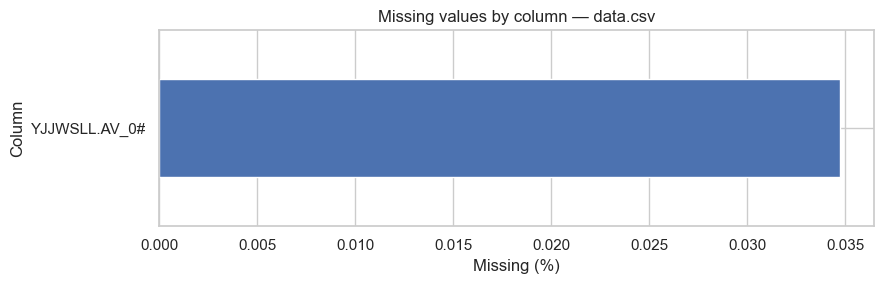

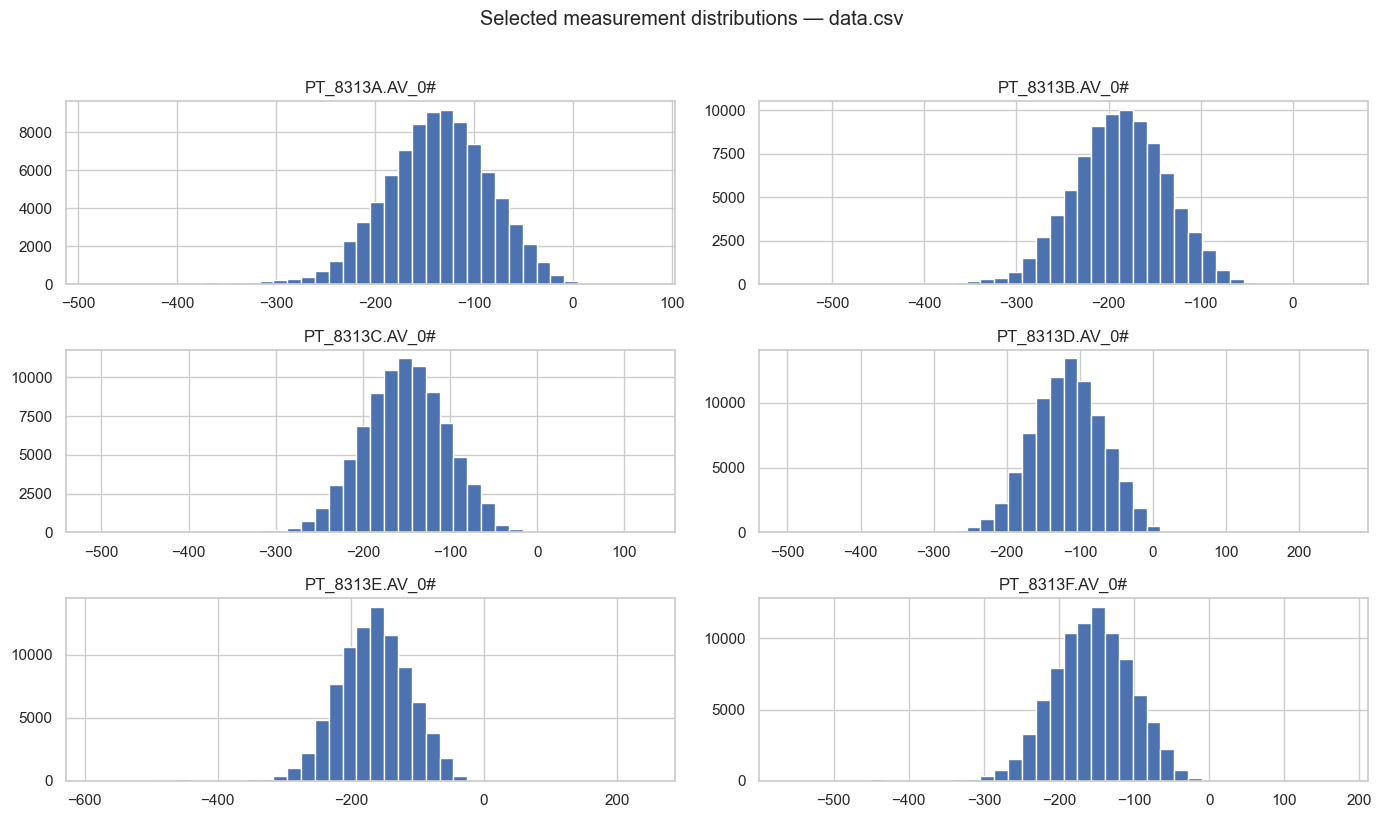

In [7]:
plot_data = data
numeric_cols = numeric_frame(plot_data).columns.tolist()

# Missing-value overview
missing_pct = plot_data.isna().mean().mul(100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]
if not missing_pct.empty:
    ax = missing_pct.head(25).sort_values().plot.barh(figsize=(9, max(3, .28 * min(len(missing_pct), 25))))
    ax.set(title="Missing values by column — data.csv", xlabel="Missing (%)", ylabel="Column")
    plt.tight_layout()
    plt.show()
else:
    print("data.csv has no missing values to plot.")

# Measurement distributions (up to six sensors)
distribution_cols = numeric_cols[:6]
if distribution_cols:
    plot_data[distribution_cols].hist(bins=40, figsize=(14, 8), layout=(-1, 2), edgecolor="white")
    plt.suptitle("Selected measurement distributions — data.csv", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No numeric measurements available for distribution plots.")

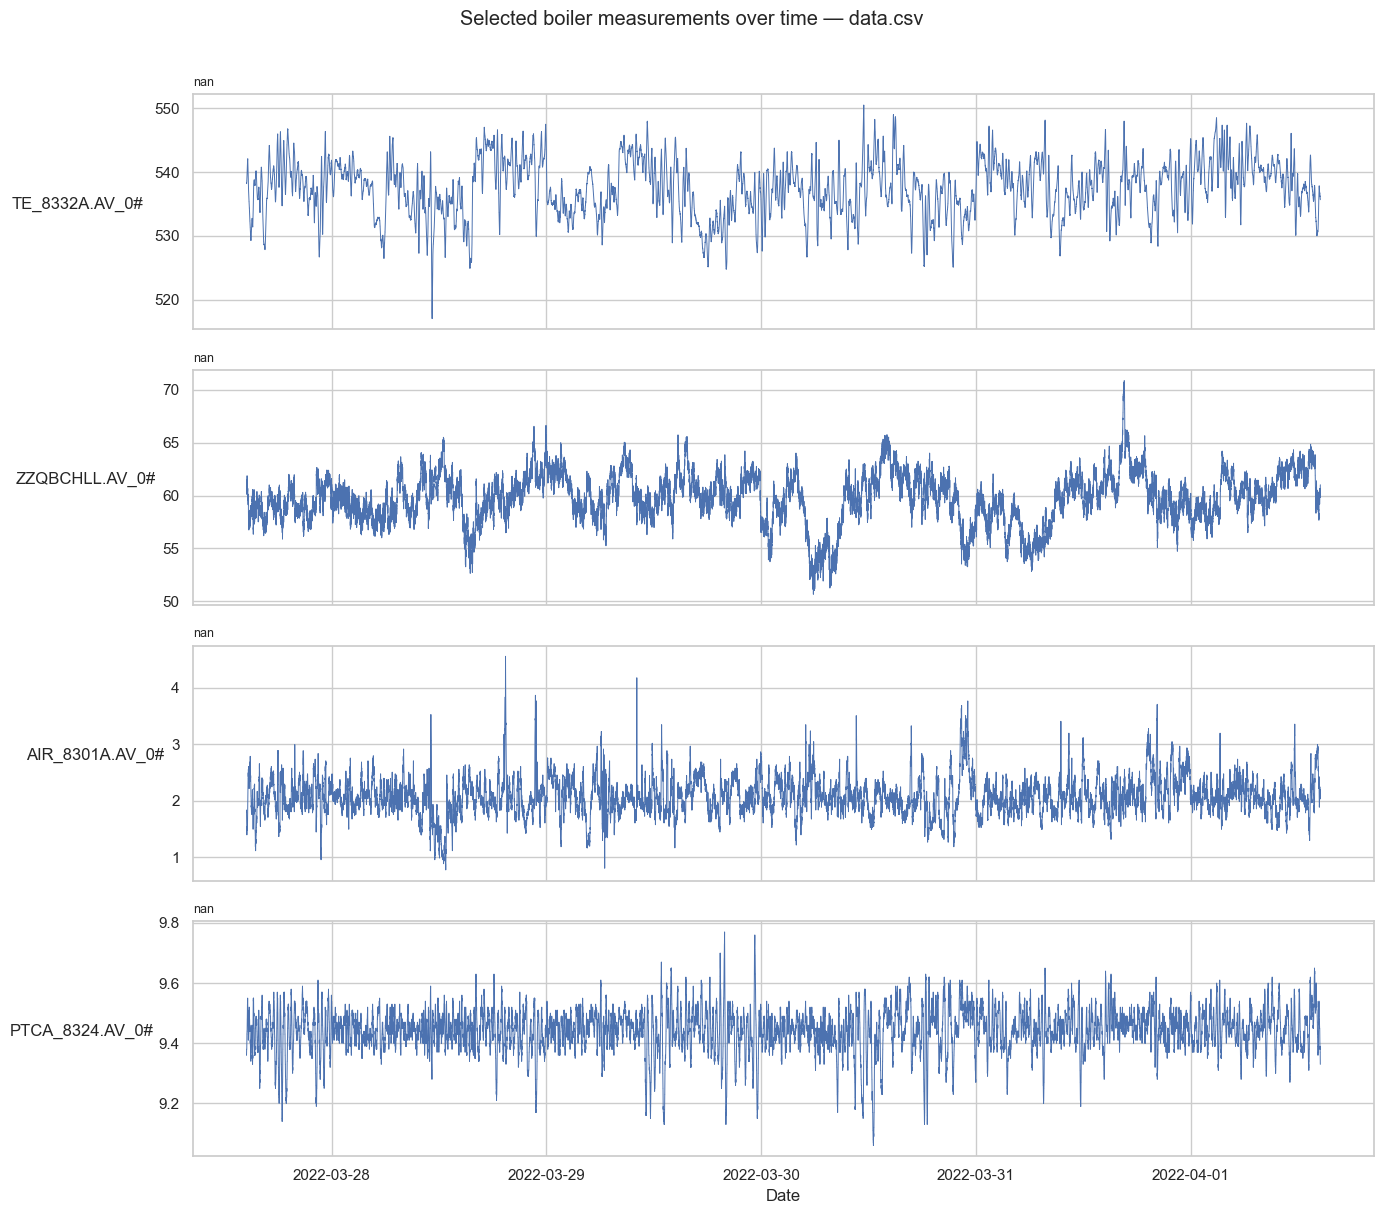

In [8]:
# Time series for representative measurements; use known process groups when present.
preferred_keys = [
    "TE_8332A.AV_0",  # boiler outlet steam temperature
    "ZZQBCHLL.AV_0",  # compensated main steam flow
    "AIR_8301A.AV_0", # flue gas oxygen
    "PTCA_8324.AV_0", # container outlet vapour pressure
]
actual_by_key = {canonical_name(c): c for c in plot_data.columns}
selected = [actual_by_key[k] for k in preferred_keys if k in actual_by_key]
selected += [c for c in numeric_cols if c not in selected][:max(0, 4 - len(selected))]
if "date" in plot_data.columns and selected:
    ordered = plot_data.dropna(subset=["date"]).sort_values("date")
    fig, axes = plt.subplots(len(selected), 1, figsize=(14, 3 * len(selected)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, col in zip(axes, selected):
        ax.plot(ordered["date"], ordered[col], linewidth=.7)
        desc = metadata_by_variant.get(canonical_name(col), {}).get("Description", col)
        ax.set_ylabel(col, rotation=0, labelpad=55)
        ax.set_title(desc, loc="left", fontsize=9)
    axes[-1].set_xlabel("Date")
    fig.suptitle("Selected boiler measurements over time — data.csv", y=1.01)
    plt.tight_layout()
    plt.show()
else:
    print("A date column and numeric measurements are required for time-series plots.")

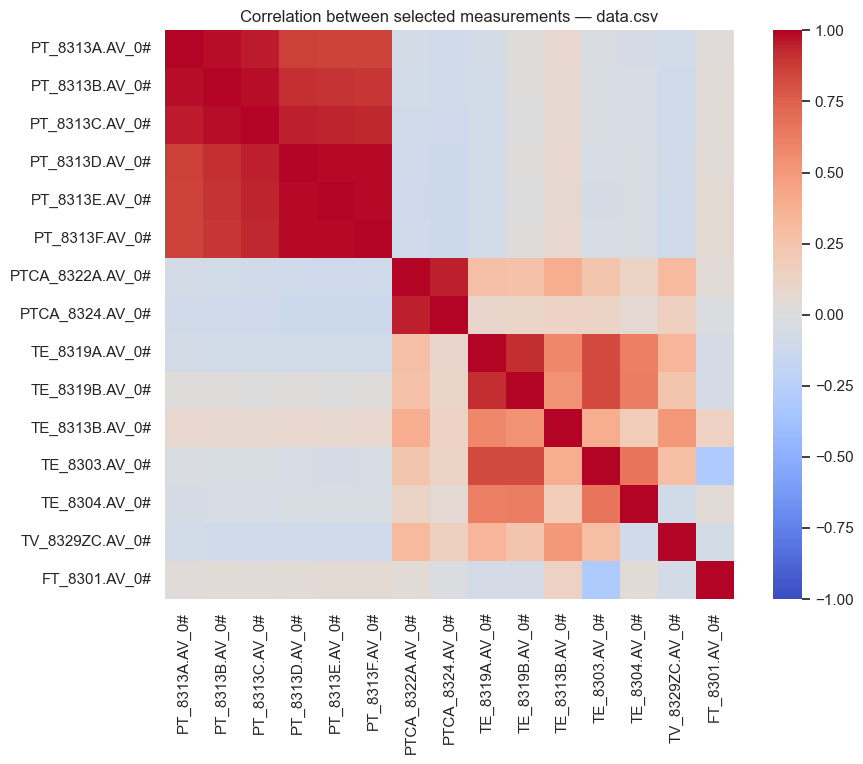

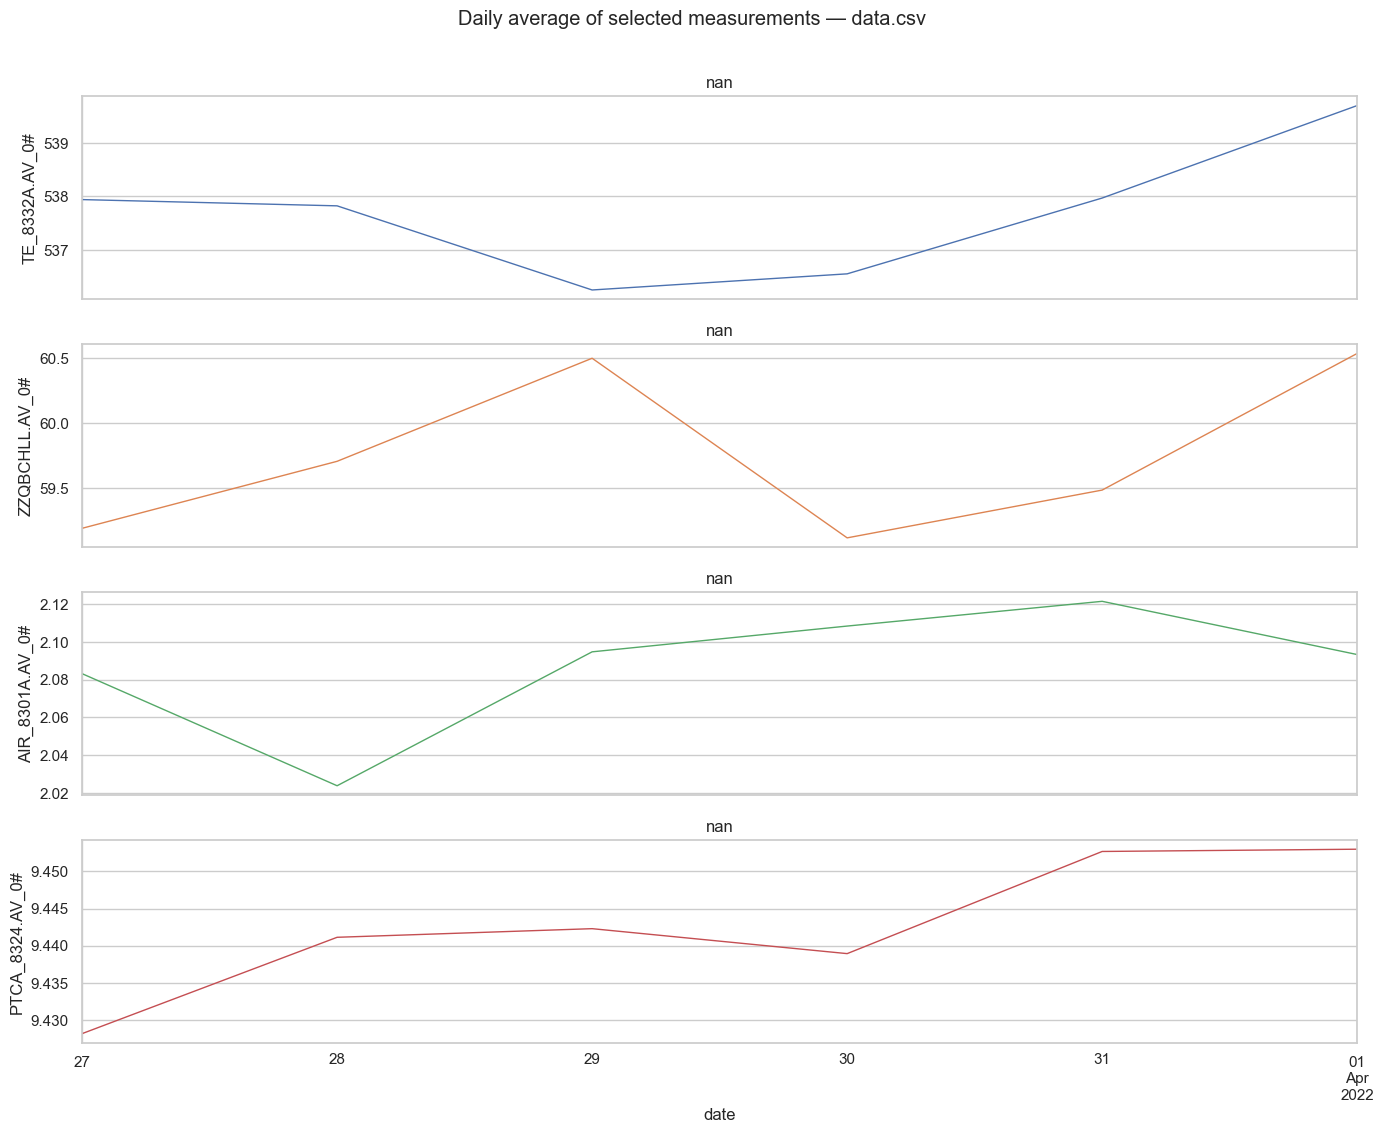

In [9]:
# Correlations among up to 15 non-constant numeric measurements.
if len(numeric_cols) >= 2:
    varying = [c for c in numeric_cols if plot_data[c].nunique(dropna=True) > 1][:15]
    if len(varying) >= 2:
        corr = plot_data[varying].corr(min_periods=2)
        size = max(8, .65 * len(varying))
        plt.figure(figsize=(size, size * .8))
        sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
        plt.title("Correlation between selected measurements — data.csv")
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough varying numeric columns for a correlation heatmap.")
else:
    print("Not enough numeric columns for a correlation heatmap.")

# Daily averages smooth short-interval sensor variation.
if "date" in plot_data.columns and numeric_cols:
    daily = (plot_data.dropna(subset=["date"])
             .set_index("date")[numeric_cols]
             .resample("D").mean())
    daily_cols = [c for c in selected if c in daily.columns][:4]
    if daily_cols and not daily.empty:
        ax = daily[daily_cols].plot(subplots=True, figsize=(14, 2.8 * len(daily_cols)),
                                    linewidth=1, legend=False)
        for axis, col in zip(np.atleast_1d(ax), daily_cols):
            axis.set_title(metadata_by_variant.get(canonical_name(col), {}).get("Description", col))
            axis.set_ylabel(col)
        plt.suptitle("Daily average of selected measurements — data.csv", y=1.01)
        plt.tight_layout()
        plt.show()
    else:
        print("No daily averages available to plot.")
else:
    print("A date column and numeric measurements are required for daily averages.")

## 7. Automatically generated observations

This final cell reports compact, data-driven facts to guide follow-up analysis. The notebook does not infer a process fault or causal relationship from correlations alone.

In [10]:
def dataset_facts(frame, name):
    print(f"{name}: {len(frame):,} rows and {len(frame.columns):,} columns.")
    if "date" in frame.columns:
        valid_dates = frame["date"].dropna()
        if not valid_dates.empty:
            print(f"  Coverage: {valid_dates.min()} through {valid_dates.max()}; "
                  f"{frame['date'].isna().sum():,} invalid timestamps.")
    missing = frame.isna().sum()
    if missing.any():
        worst = missing[missing > 0].sort_values(ascending=False).head(3)
        print("  Most-missing fields:", "; ".join(f"{col} ({count:,})" for col, count in worst.items()))
    else:
        print("  No missing cells detected.")
    print(f"  Exact duplicate rows: {frame.duplicated().sum():,}.")

dataset_facts(data, "data.csv")
dataset_facts(autoreg, "data_AutoReg.csv")
if comparison_rows:
    valid_comparison = comparison.dropna(subset=["mean_absolute_difference"])
    if not valid_comparison.empty:
        largest = valid_comparison.sort_values("mean_absolute_difference", ascending=False).iloc[0]
        closest = valid_comparison.sort_values("mean_absolute_difference").iloc[0]
        print(f"\nComparison on paired timestamps ({len(aligned):,}): "
              f"largest mean absolute difference is {largest['measurement']} "
              f"({largest['mean_absolute_difference']:.4g}); smallest is {closest['measurement']} "
              f"({closest['mean_absolute_difference']:.4g}).")
print("\nInterpretation note: validate units, operating regimes, sensor limits, and data provenance "
      "before treating outliers or dataset differences as operational anomalies.")

data.csv: 86,400 rows and 31 columns.
  Coverage: 2022-03-27 14:28:54 through 2022-04-01 14:28:49; 0 invalid timestamps.
  Most-missing fields: YJJWSLL.AV_0# (30)
  Exact duplicate rows: 0.
data_AutoReg.csv: 86,400 rows and 31 columns.
  Coverage: 2022-03-27 14:28:54 through 2022-04-01 14:28:49; 0 invalid timestamps.
  No missing cells detected.
  Exact duplicate rows: 0.

Comparison on paired timestamps (86,400): largest mean absolute difference is AIR_8301A.AV_0 (0); smallest is AIR_8301A.AV_0 (0).

Interpretation note: validate units, operating regimes, sensor limits, and data provenance before treating outliers or dataset differences as operational anomalies.
